<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/7_2_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%writefile gorev2_gurultu.cpp
#include <iostream>
#include <vector>
#include <cmath>
#include <fstream>
#include <random>
#include <algorithm>

const double PI = std::acos(-1.0);

// 1. Önceki adımdan hatırladığımız Sinüs Üretici Fonksiyon (Test verisi için)
void generateSineWave(std::vector<double>& vec, double amplitude, double frequency, double phase) {
    size_t n = vec.size();
    for (size_t i = 0; i < n; ++i) {
        vec[i] = amplitude * std::sin(2.0 * PI * frequency * (static_cast<double>(i) / n) + phase);
    }
}

// 2. GÖREV: Vektöre Genlik ve Oran Bazlı Rastgele Gürültü Ekleyen Fonksiyon
void addNoise(std::vector<double>& vec, double noise_ratio) {
    // Gürültü oranı [0, 1] aralığı dışındaysa sınırla
    noise_ratio = std::max(0.0, std::min(1.0, noise_ratio));

    // Vektördeki maksimum mutlak genliği bul
    double max_amplitude = 0.0;
    for (double val : vec) {
        if (std::abs(val) > max_amplitude) {
            max_amplitude = std::abs(val);
        }
    }

    // Maksimum eklenecek/çıkarılacak gürültü miktarı (Genlik * Oran)
    double noise_bound = max_amplitude * noise_ratio;

    // C++11 Rastgele Sayı Üretici (Uniform Dağılım)
    std::random_device rd;
    std::mt19937 gen(rd());
    std::uniform_real_distribution<> dis(-noise_bound, noise_bound);

    // Her elemana rastgele gürültüyü ekle
    for (double& val : vec) {
        val += dis(gen);
    }
}

int main() {
    size_t vectorSize = 256; // 2^8 boyutunda vektör

    // Test sinyali için orijinal vektörü oluştur
    std::vector<double> original_signal(vectorSize);
    generateSineWave(original_signal, 50.0, 4.0, 0.0); // Genlik 50, 4 periyot

    // Gürültülü sinyal için orijinal vektörü kopyala
    std::vector<double> noisy_signal = original_signal;

    // Gürültü ekleme fonksiyonunu çağır (%20 gürültü oranı = 0.20)
    double noiseRatio = 0.20;
    addNoise(noisy_signal, noiseRatio);

    // Görselleştirme için her iki sinyali CSV dosyasına yaz
    std::ofstream outFile("gurultu_verisi.csv");
    outFile << "Index,Original,Noisy\n";
    for (size_t i = 0; i < vectorSize; ++i) {
        outFile << i << "," << original_signal[i] << "," << noisy_signal[i] << "\n";
    }
    outFile.close();

    std::cout << "Sinyal uretildi, %" << (noiseRatio * 100)
              << " oraninda gurultu eklendi ve 'gurultu_verisi.csv' dosyasina kaydedildi." << std::endl;

    return 0;
}

Writing gorev2_gurultu.cpp


In [2]:
!g++ gorev2_gurultu.cpp -o gorev2_gurultu
!./gorev2_gurultu

Sinyal uretildi, %20 oraninda gurultu eklendi ve 'gurultu_verisi.csv' dosyasina kaydedildi.


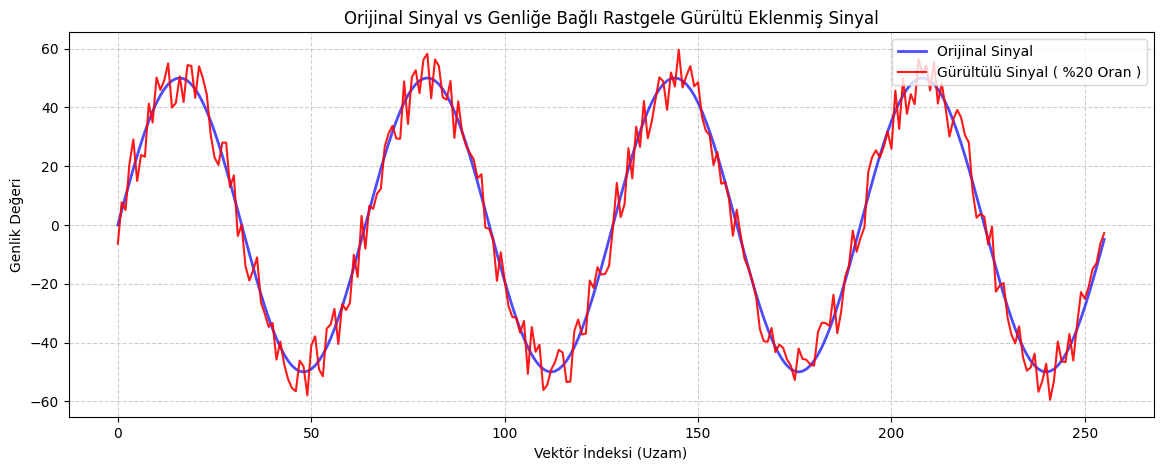

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# C++ tarafından üretilen CSV'yi oku
df = pd.read_csv('gurultu_verisi.csv')

# Grafikleri çizdir
plt.figure(figsize=(14, 5))

# Orijinal Sinyal (Mavi)
plt.plot(df['Index'], df['Original'], color='blue', label='Orijinal Sinyal', linewidth=2, alpha=0.7)

# Gürültülü Sinyal (Kırmızı, kesikli)
plt.plot(df['Index'], df['Noisy'], color='red', label='Gürültülü Sinyal ( %20 Oran )', linewidth=1.5, alpha=0.9)

plt.title('Orijinal Sinyal vs Genliğe Bağlı Rastgele Gürültü Eklenmiş Sinyal')
plt.xlabel('Vektör İndeksi (Uzam)')
plt.ylabel('Genlik Değeri')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()